# Data Cleaning


In [1]:
import sys
from pathlib import Path

# Add project root directory to sys.path
sys.path.append(str(Path.cwd().parent))

# Now import your custom modules
import pandas as pd
from plotnine import *
import numpy as np
import seaborn as sns
from scripts.profiling import *

#### Import the dataset

In [2]:
delivery_raw = pd.read_csv('../data/dim_delivery_zone.csv')
kitchen_raw = pd.read_csv('../data/dim_kitchen.csv')
rider_raw = pd.read_csv('../data/dim_rider.csv')
time_raw = pd.read_csv('../data/dim_time_slot.csv')
order_raw = pd.read_csv('../data/fact_orders.csv')

### Profiling

Table 1.1   
**Fact Order**

In [3]:
display(order_raw)

,order_id,kitchen_id,zone_id,rider_id,time_slot_id,order_date,order_value_ngn,delivery_distance_km,promised_delivery_min,actual_delivery_min,traffic_friction_score,food_temp_on_arrival_c,customer_rating,delivery_cost_ngn,order_profit_ngn
0,val_0,KIT-LK-001,val_17,val_5,val_27,1/1/2023,55547.355750,2.094056,819,187,6.842537,774.811302,3.050304,3990.889610,770.448149
1,val_1,KIT-LK-001,val_7,val_57,val_8,1/1/2023,76539.463520,13.115810,244,147,5.151269,575.344313,2.028476,5093.975840,471.500605
2,val_2,KIT-LK-001,val_4,val_39,val_1,1/1/2023,34520.268720,30.995966,704,957,8.135522,619.910548,3.657403,660.785739,695.249519
3,val_3,KIT-IK-001,val_18,val_32,val_19,1/1/2023,81371.462870,27.720964,792,871,5.953026,520.754665,1.074567,10246.714590,584.319348
4,val_4,KIT-YB-001,val_13,val_0,val_28,1/1/2023,120484.913000,4.033347,900,881,5.118829,613.951723,3.880358,10387.325650,170.288819
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,val_4995,KIT-YB-001,val_12,val_29,val_37,12/30/2024,66950.751720,13.579382,340,92,1.851494,480.348609,3.986100,10759.268410,642.028071
4996,val_4996,KIT-SU-001,val_9,val_56,val_3,12/30/2024,76276.064130,18.900230,955,839,8.327525,681.291698,2.084170,3288.144331,338.017230
4997,val_4997,KIT-YB-001,val_7,val_5,val_24,12/30/2024,69943.648080,11.338230,896,506,4.709823,554.337631,1.229928,5048.422160,376.326468
4998,val_4998,KIT-IK-001,val_14,val_12,val_19,12/30/2024,77658.995900,16.861767,916,565,6.400225,287.299065,4.165457,10784.705660,858.535953



═════════════════════════════════════════════════════════════════
  AUTOMATED PROFILING REPORT
  Shape : 5,000 rows × 15 columns

═════════════════════════════════════════════════════════════════

─────────────────────────────────────────────────────────────────
  1. STRUCTURE & DATA TYPES
─────────────────────────────────────────────────────────────────
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   order_id                5000 non-null   str    
 1   kitchen_id              5000 non-null   str    
 2   zone_id                 5000 non-null   str    
 3   rider_id                5000 non-null   str    
 4   time_slot_id            5000 non-null   str    
 5   order_date              5000 non-null   str    
 6   order_value_ngn         5000 non-null   float64
 7   delivery_distance_km    5000 non-null   float64
 8   promised_de

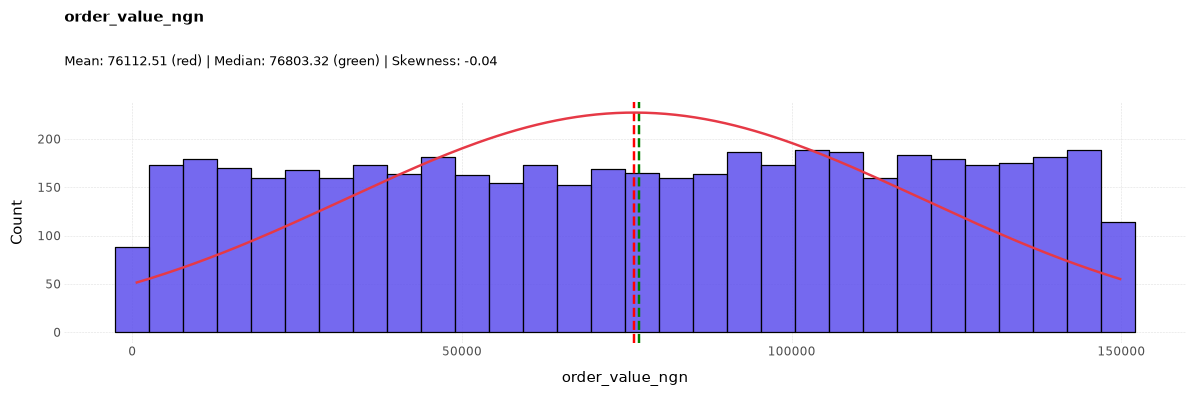

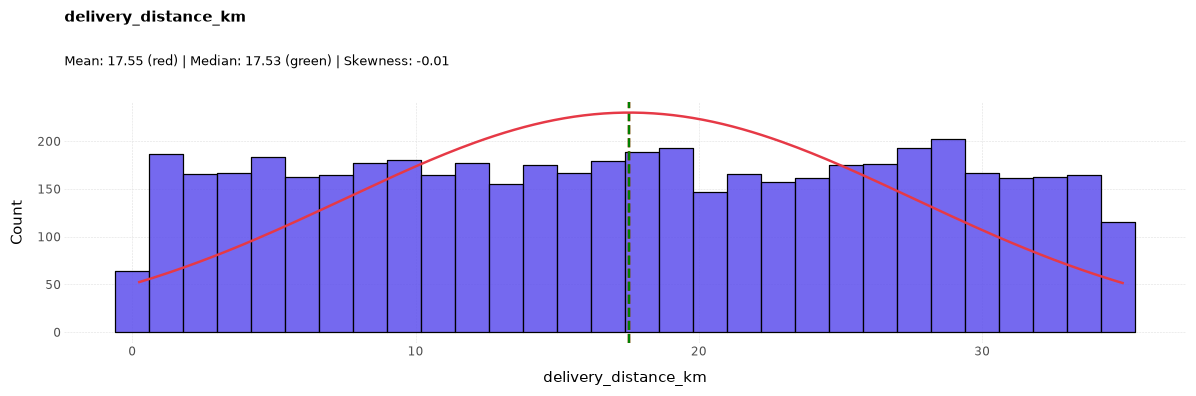

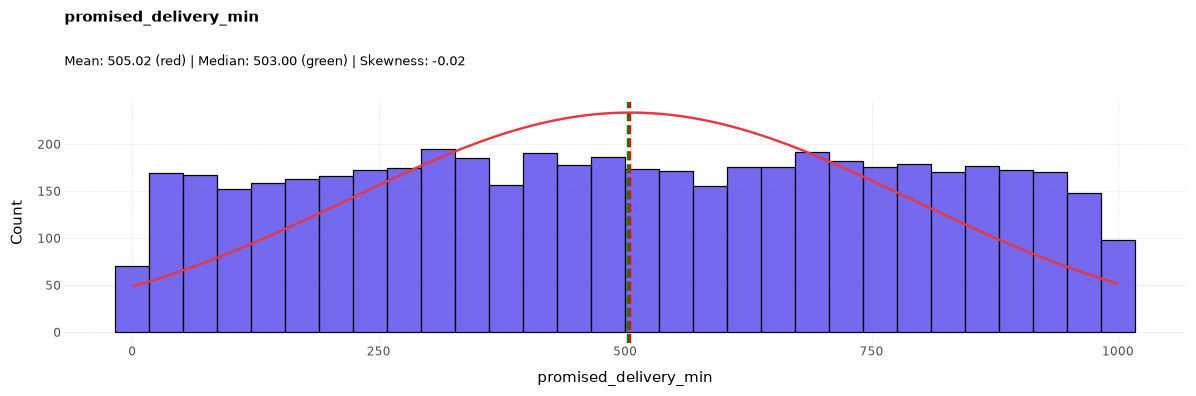

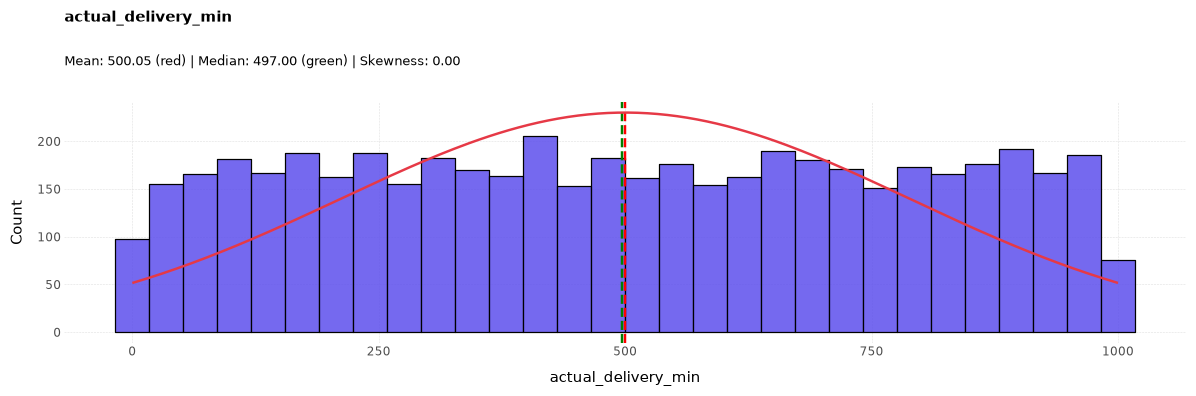

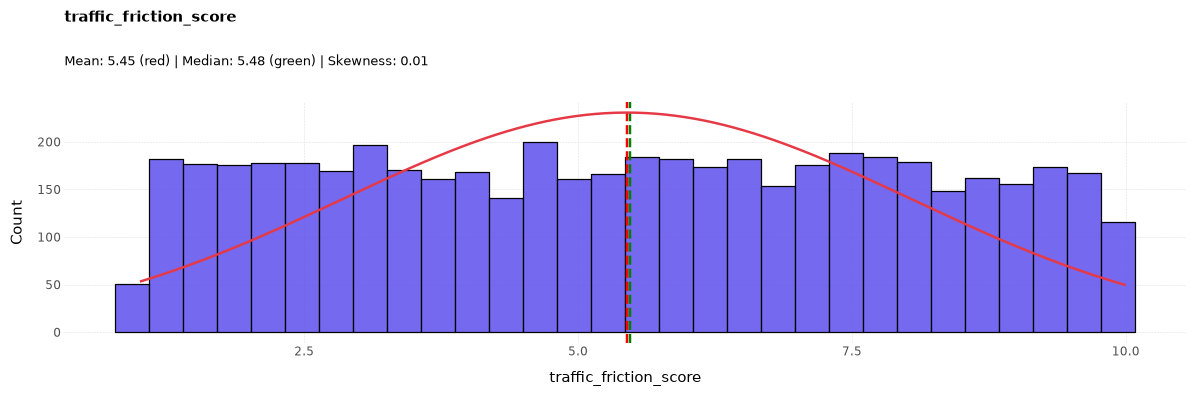

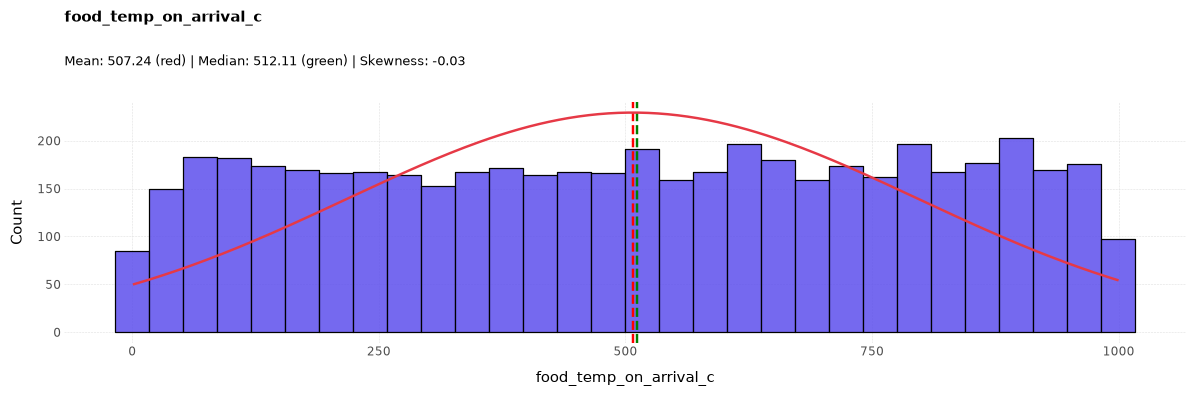

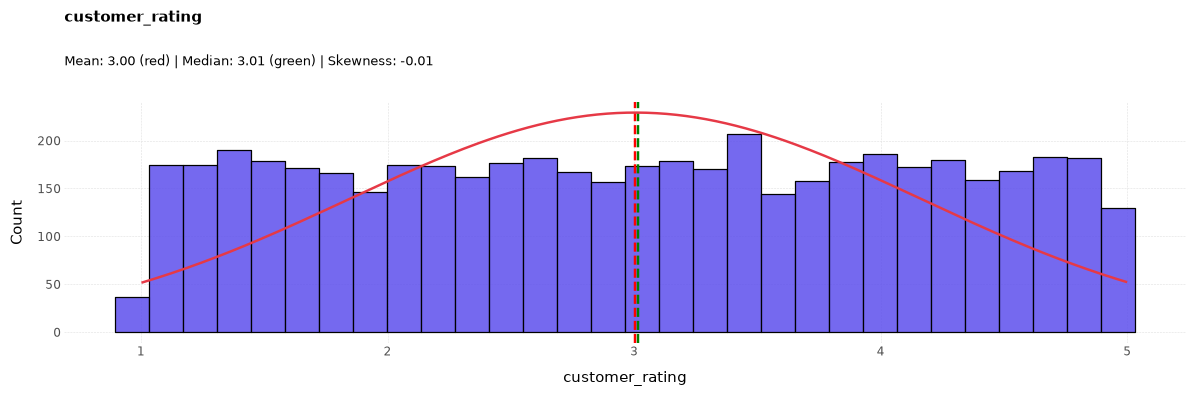

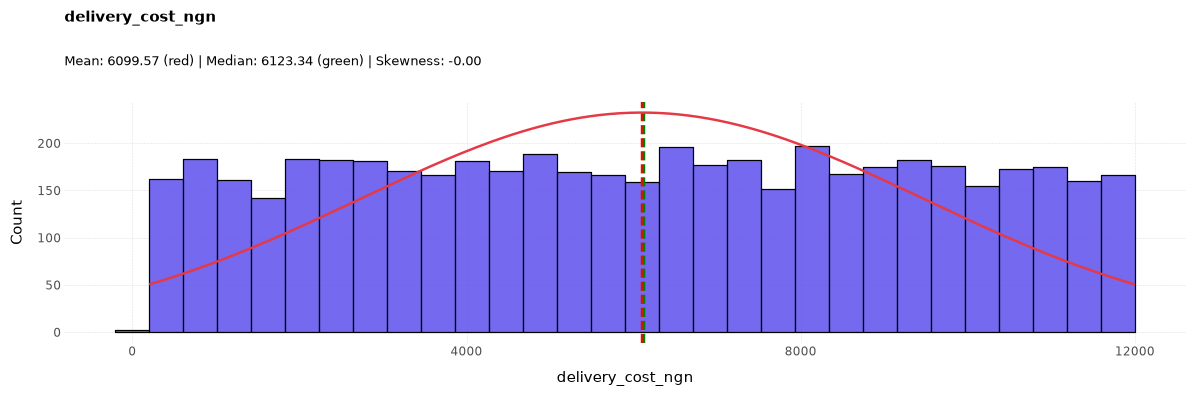

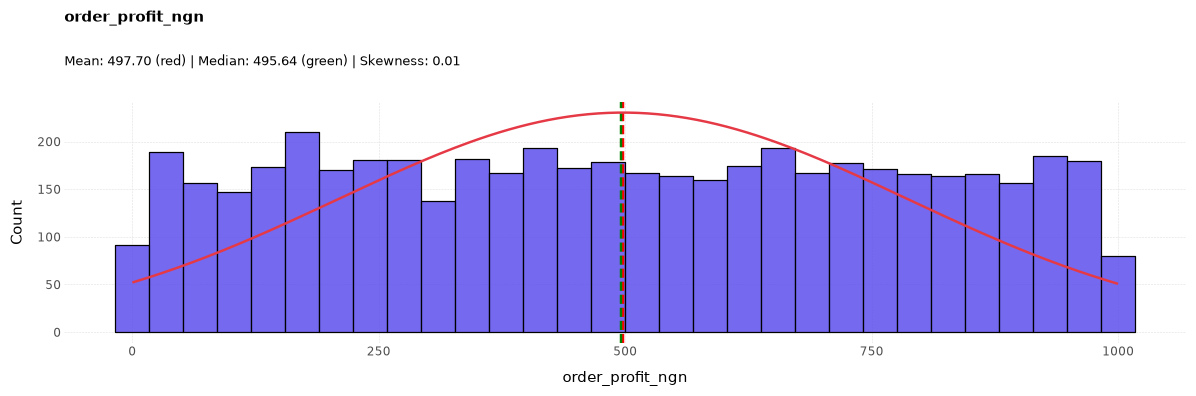


─────────────────────────────────────────────────────────────────
  7. OUTLIERS — IQR Method (numeric columns)
─────────────────────────────────────────────────────────────────

  Column                          Outliers       %  Fence
  ────────────────────────────────────────────────────────────
  order_value_ngn                        0    0.0%  [-75,969.9, 227,995.2]
  delivery_distance_km                   0    0.0%  [-17.7, 53.0]
  promised_delivery_min                  0    0.0%  [-463.5, 1,476.5]
  actual_delivery_min                    0    0.0%  [-503.5, 1,500.5]
  traffic_friction_score                 0    0.0%  [-3.6, 14.4]
  food_temp_on_arrival_c                 0    0.0%  [-506.4, 1,520.8]
  customer_rating                        0    0.0%  [-1.0, 7.0]
  delivery_cost_ngn                      0    0.0%  [-5,514.6, 17,693.6]
  order_profit_ngn                       0    0.0%  [-504.9, 1,496.2]

─────────────────────────────────────────────────────────────────

  ✔  No o

In [4]:
profile(order_raw)

In [5]:
plausible = (order_raw['actual_delivery_min'] >= 5) & (order_raw['actual_delivery_min'] <= 120)
print(f"{(~plausible).sum()} of {len(order_raw)} rows have an impossible delivery time")

4426 of 5000 rows have an impossible delivery time


Table 1.2   
**Rider**

In [6]:
rider_raw.head()

,rider_id,rider_name,assigned_kitchen_id,vehicle_type,experience_months,avg_speed_kmh,avg_rider_rating,is_active
0,val_0,Tunde Adeyemi,KIT-LK-001,Electric Motorcycle,44,937.826455,3.751853,True
1,val_1,Jide Martins,KIT-LK-001,Tricycle (Keke),19,571.728052,2.859744,True
2,val_2,Yusuf Abdullahi,KIT-LK-001,Bicycle,49,473.489401,2.534841,False
3,val_3,Bayo Adeleke,KIT-IK-001,Motorcycle (Okada),35,266.975663,3.074140,True
4,val_4,Nnamdi Obi,KIT-SU-001,Bicycle,33,331.568997,2.829556,False



═════════════════════════════════════════════════════════════════
  AUTOMATED PROFILING REPORT
  Shape : 60 rows × 8 columns

═════════════════════════════════════════════════════════════════

─────────────────────────────────────────────────────────────────
  1. STRUCTURE & DATA TYPES
─────────────────────────────────────────────────────────────────
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   rider_id             60 non-null     str    
 1   rider_name           60 non-null     str    
 2   assigned_kitchen_id  60 non-null     str    
 3   vehicle_type         60 non-null     str    
 4   experience_months    60 non-null     int64  
 5   avg_speed_kmh        60 non-null     float64
 6   avg_rider_rating     60 non-null     float64
 7   is_active            60 non-null     bool   
dtypes: bool(1), float64(2), int64(1), str(4)
memory us

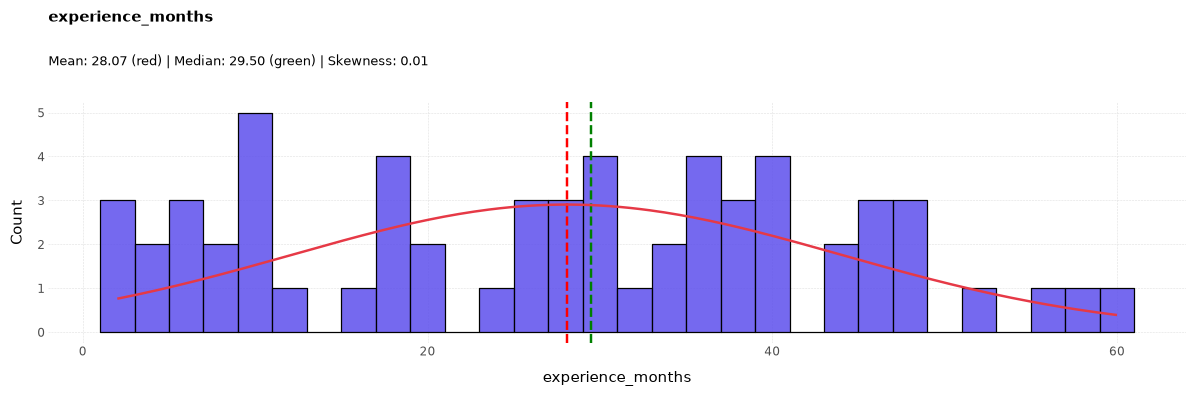

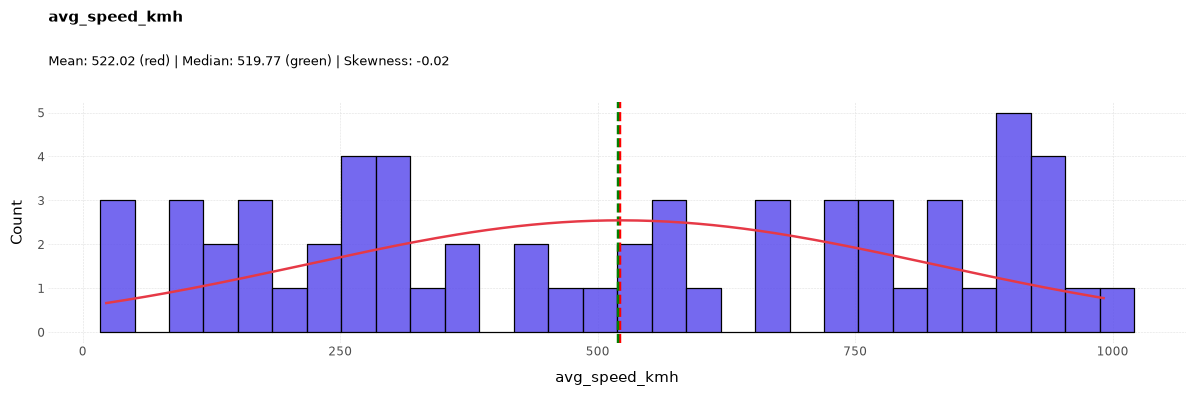

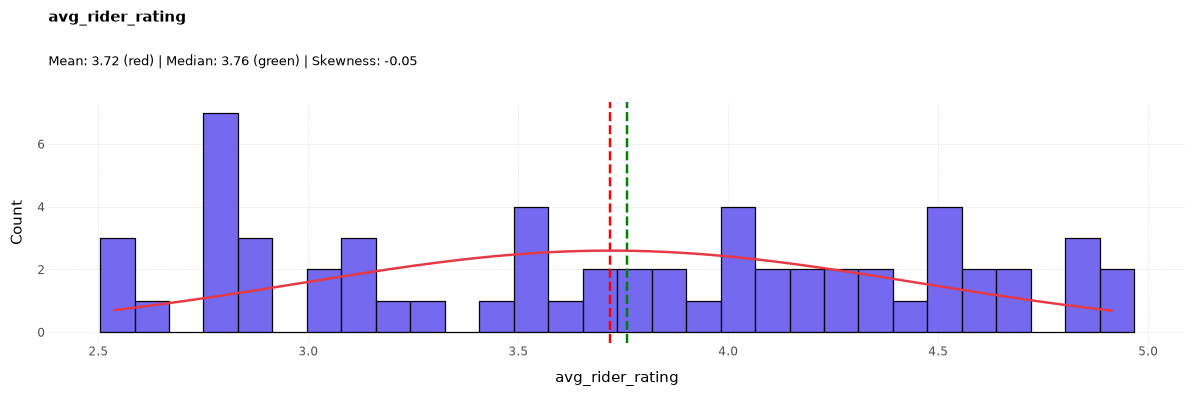


─────────────────────────────────────────────────────────────────
  7. OUTLIERS — IQR Method (numeric columns)
─────────────────────────────────────────────────────────────────

  Column                          Outliers       %  Fence
  ────────────────────────────────────────────────────────────
  experience_months                      0    0.0%  [-30.6, 82.4]
  avg_speed_kmh                          0    0.0%  [-567.1, 1,640.6]
  avg_rider_rating                       0    0.0%  [1.1, 6.3]

─────────────────────────────────────────────────────────────────

  ✔  No outliers detected in any numeric column.

─────────────────────────────────────────────────────────────────
  8. CATEGORICAL COLUMNS
─────────────────────────────────────────────────────────────────

  rider_id — 60 unique values
  Top 3: {'val_0': np.int64(1), 'val_1': np.int64(1), 'val_2': np.int64(1)}

  ⚠  'rider_id' has 60 unique values — likely a free-text or ID column. Avoid using as a categorical feature.

  rider

In [7]:
profile(rider_raw)

Table 1.3   
**Delivery**

In [8]:
delivery_raw.head()

,zone_id,zone_name,zone_lga,zone_tier,avg_zone_traffic_index,zone_population_density,baseline_delivery_min,is_restricted_zone
0,val_0,Isolo,Mushin,Tier 3 - Extended Zone,4.028381,Very High,17,False
1,val_1,Ajegunle,Ikeja,Tier 1 - Core Zone,5.622848,Low,36,True
2,val_2,Ketu,Eti-Osa,Tier 2 - Adjacent Zone,8.033916,High,12,False
3,val_3,Lekki Phase 2,Surulere,Tier 2 - Adjacent Zone,6.524923,Medium,37,True
4,val_4,Bariga,Agege,Tier 3 - Extended Zone,7.693817,High,32,True



═════════════════════════════════════════════════════════════════
  AUTOMATED PROFILING REPORT
  Shape : 20 rows × 8 columns

═════════════════════════════════════════════════════════════════

─────────────────────────────────────────────────────────────────
  1. STRUCTURE & DATA TYPES
─────────────────────────────────────────────────────────────────
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   zone_id                  20 non-null     str    
 1   zone_name                20 non-null     str    
 2   zone_lga                 20 non-null     str    
 3   zone_tier                20 non-null     str    
 4   avg_zone_traffic_index   20 non-null     float64
 5   zone_population_density  20 non-null     str    
 6   baseline_delivery_min    20 non-null     int64  
 7   is_restricted_zone       20 non-null     bool   
dtypes: bool(1)

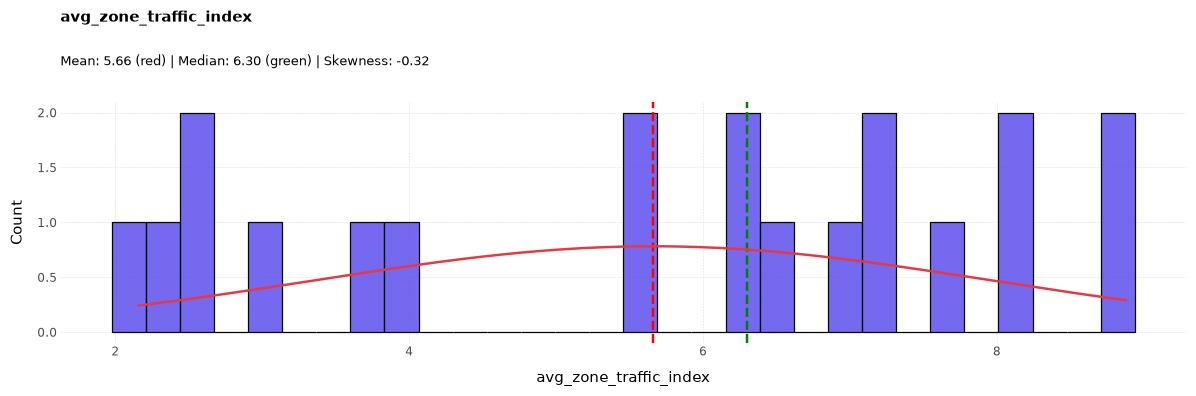

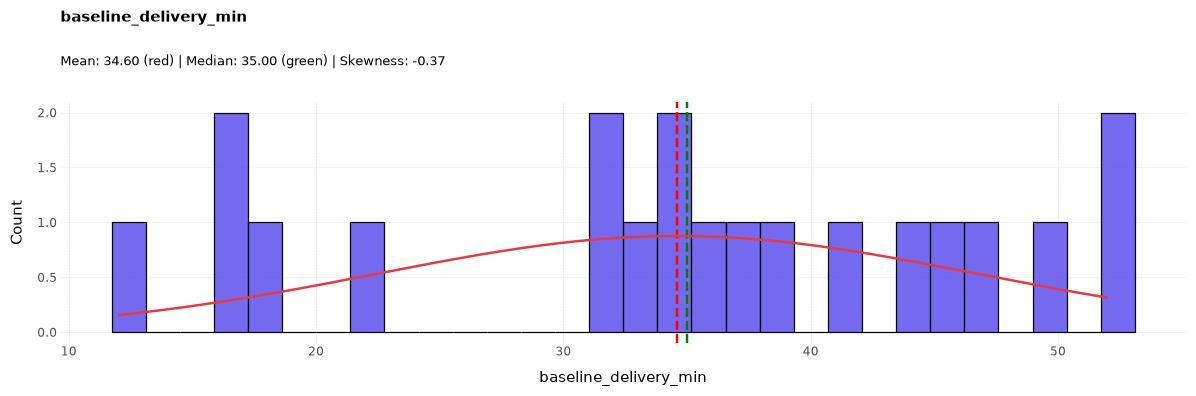


─────────────────────────────────────────────────────────────────
  7. OUTLIERS — IQR Method (numeric columns)
─────────────────────────────────────────────────────────────────

  Column                          Outliers       %  Fence
  ────────────────────────────────────────────────────────────
  avg_zone_traffic_index                 0    0.0%  [-2.1, 12.9]
  baseline_delivery_min                  0    0.0%  [7.4, 66.4]

─────────────────────────────────────────────────────────────────

  ✔  No outliers detected in any numeric column.

─────────────────────────────────────────────────────────────────
  8. CATEGORICAL COLUMNS
─────────────────────────────────────────────────────────────────

  zone_id — 20 unique values
  Top 3: {'val_0': np.int64(1), 'val_1': np.int64(1), 'val_2': np.int64(1)}

  zone_name — 15 unique values
  Top 3: {'Ajegunle': np.int64(2), 'Bariga': np.int64(2), 'Shomolu': np.int64(2)}

  zone_lga — 9 unique values
  Top 3: {'Eti-Osa': np.int64(6), 'Mushin': np

In [9]:
profile(delivery_raw)

Table 1.4     
**Kitchen**

In [10]:
kitchen_raw.head()

,kitchen_id,kitchen_name,lga,latitude,longitude,kitchen_capacity_orders_hr,date_opened,is_active
0,KIT-YB-001,Golden Wok Lekki Phase 1,Yaba,6.574617,3.411576,45,3/21/2023,True
1,KIT-SU-001,Golden Wok Surulere Hub,Yaba,6.579352,3.533888,40,4/4/2021,False
2,KIT-IK-001,Golden Wok Yaba Central,Ikeja,6.454342,3.471650,40,4/23/2024,False
3,KIT-LK-001,Golden Wok Ikeja GRA,Surulere,6.515573,3.511008,30,7/12/2023,True



═════════════════════════════════════════════════════════════════
  AUTOMATED PROFILING REPORT
  Shape : 4 rows × 8 columns

═════════════════════════════════════════════════════════════════

─────────────────────────────────────────────────────────────────
  1. STRUCTURE & DATA TYPES
─────────────────────────────────────────────────────────────────
<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   kitchen_id                  4 non-null      str    
 1   kitchen_name                4 non-null      str    
 2   lga                         4 non-null      str    
 3   latitude                    4 non-null      float64
 4   longitude                   4 non-null      float64
 5   kitchen_capacity_orders_hr  4 non-null      int64  
 6   date_opened                 4 non-null      str    
 7   is_active                   4 non-null  

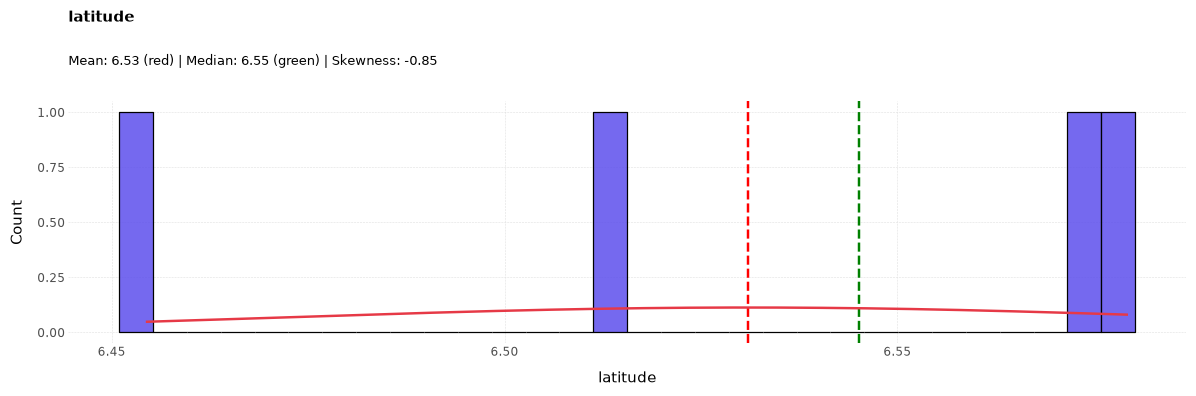

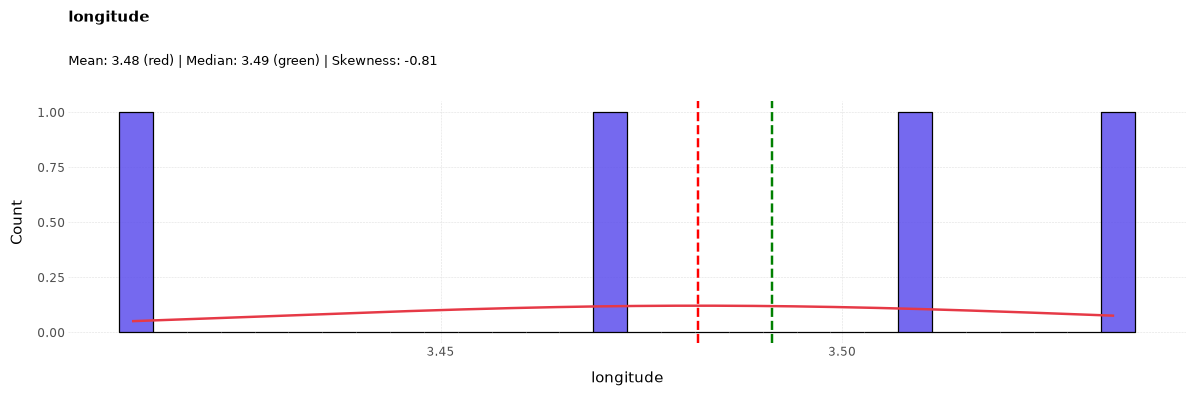

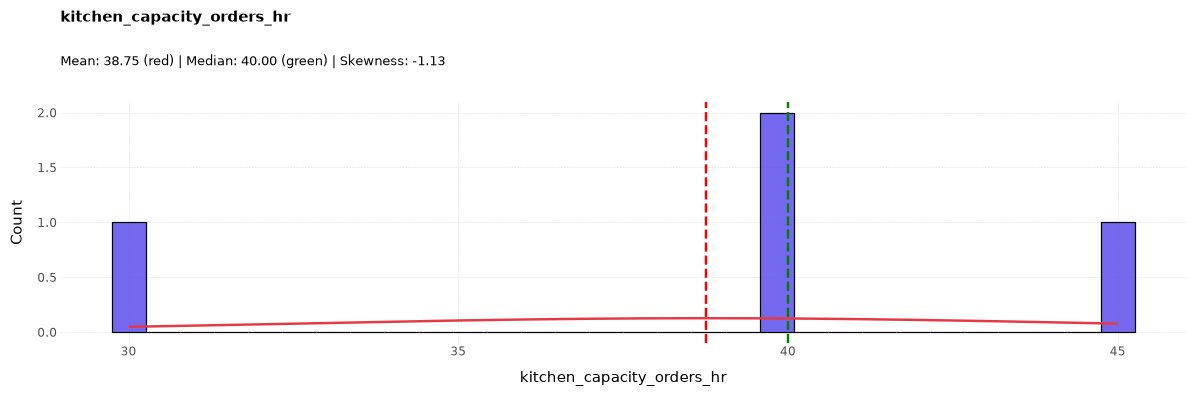


─────────────────────────────────────────────────────────────────
  7. OUTLIERS — IQR Method (numeric columns)
─────────────────────────────────────────────────────────────────

  Column                          Outliers       %  Fence
  ────────────────────────────────────────────────────────────
  latitude                               0    0.0%  [6.4, 6.7]
  longitude                              0    0.0%  [3.4, 3.6]
  kitchen_capacity_orders_hr     ⚠       1   25.0%  [31.9, 46.9]

─────────────────────────────────────────────────────────────────

  ⚠  1 column(s) have outliers.

  ▶  Review each flagged column — outliers are not automatically errors.

  ▶  Ask: is this an entry error, a legitimate extreme event, or the most interesting observation in the dataset?

  ▶  For modelling: consider whether to keep, cap (winsorise), or log-transform. Never remove without investigation.

─────────────────────────────────────────────────────────────────
  8. CATEGORICAL COLUMNS
──────────

In [11]:
profile(kitchen_raw)

Table 1.5   
**Time**

In [12]:
time_raw.head()

,time_slot_id,slot_label,hour_of_day,day_of_week,is_weekend,is_rush_hour,meal_period,weather_condition
0,val_0,20:00-21:00,07:23,Wednesday,True,Yes,Afternoon,Thunderstorm
1,val_1,12:00-13:00,08:26,Friday,True,Yes,Early Dinner,Overcast
2,val_2,15:00-16:00,04:31,Sunday,True,Yes,Afternoon,Sunny
3,val_3,11:00-12:00,02:95,Monday,False,No,Mid-Morning,Thunderstorm
4,val_4,11:00-12:00,09:69,Monday,False,No,Breakfast,Humid/Hazy


In [13]:
profile(time_raw)


═════════════════════════════════════════════════════════════════
  AUTOMATED PROFILING REPORT
  Shape : 48 rows × 8 columns

═════════════════════════════════════════════════════════════════

─────────────────────────────────────────────────────────────────
  1. STRUCTURE & DATA TYPES
─────────────────────────────────────────────────────────────────
<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   time_slot_id       48 non-null     str  
 1   slot_label         48 non-null     str  
 2   hour_of_day        48 non-null     str  
 3   day_of_week        48 non-null     str  
 4   is_weekend         48 non-null     bool 
 5   is_rush_hour       48 non-null     str  
 6   meal_period        48 non-null     str  
 7   weather_condition  48 non-null     str  
dtypes: bool(1), str(7)
memory usage: 2.8 KB
None

────────────────────────────────────────────

In [14]:
#!pip freeze > requirements.txt